# Tercera Práctica Calificada – Minería de Datos Avanzado
### Caso Series de Tiempo: Futuros de Oro (GC=F)
Alumno: Quiliche Chavez Andres  
Profesor: Dr. Richard Fernando Fernández Vásquez

### Instalación de librerías

In [1]:
!pip install -q --disable-pip-version-check yfinance curl_cffi h2o

### Importación de librerías

In [2]:
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random

import yfinance as yf
import sklearn.metrics as metrics
from sklearn.preprocessing import MinMaxScaler

import h2o
from h2o.estimators import H2ORandomForestEstimator, H2ODeepLearningEstimator
from h2o.automl import H2OAutoML

import tensorflow as tf
import keras
from keras.models import Sequential
from keras.layers import Dense, LSTM, GRU, Input

# Ocultar avisos (H2O, statsmodels y TensorFlow); va después de importar h2o porque h2o activa sus propios avisos
warnings.filterwarnings("ignore")
tf.get_logger().setLevel("ERROR")

# Semilla única (123) para todo el notebook: Python, NumPy, TensorFlow/Keras y H2O
SEED = 123
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()   # operaciones deterministas en TensorFlow

## Comprensión de los datos

In [3]:
# Descarga de los futuros de oro desde Yahoo Finance
# (en yfinance el parámetro 'end' es exclusivo; por eso se usa 2026-10-01 para incluir el 30/09/2026)
gold = yf.Ticker("GC=F")
serie = gold.history(start="2010-01-01", end="2026-10-01")

# Se quita la zona horaria del índice para poder filtrar por fechas sin problemas
serie.index = pd.to_datetime(serie.index).tz_localize(None)
serie.head()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2010-01-04,1117.699951,1122.300049,1097.099976,1117.699951,184,0.0,0.0
2010-01-05,1118.099976,1126.500000,1115.000000,1118.099976,53,0.0,0.0
2010-01-06,1135.900024,1139.199951,1120.699951,1135.900024,363,0.0,0.0
2010-01-07,1133.099976,1133.099976,1129.199951,1133.099976,56,0.0,0.0
2010-01-08,1138.199951,1138.199951,1122.699951,1138.199951,54,0.0,0.0


In [4]:
serie.tail()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2026-09-24,4324.399902,4338.000000,4278.299805,4298.000000,164814,0.0,0.0
2026-09-25,4309.500000,4351.600098,4289.200195,4321.200195,140092,0.0,0.0
2026-09-28,4315.000000,4315.600098,4143.100098,4168.399902,229031,0.0,0.0
2026-09-29,4150.100098,4218.100098,4145.200195,4179.700195,149747,0.0,0.0
2026-09-30,4216.200195,4251.100098,4178.200195,4186.700195,156277,0.0,0.0


In [5]:
serie.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 4211 entries, 2010-01-04 to 2026-09-30
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Open          4211 non-null   float64
 1   High          4211 non-null   float64
 2   Low           4211 non-null   float64
 3   Close         4211 non-null   float64
 4   Volume        4211 non-null   int64  
 5   Dividends     4211 non-null   float64
 6   Stock Splits  4211 non-null   float64
dtypes: float64(6), int64(1)
memory usage: 263.2 KB


In [6]:
serie.to_csv('serie_oro.csv')

In [7]:
# Selección de la variable de interés: precio de cierre
serie_close = serie.filter(['Close'])
serie_close.describe().T

,count,mean,std,min,25%,50%,75%,max
Close,4211.0,1796.349181,833.845667,1050.800049,1273.649963,1562.599976,1880.950012,5318.399902


## Ploteo de la serie de tiempo

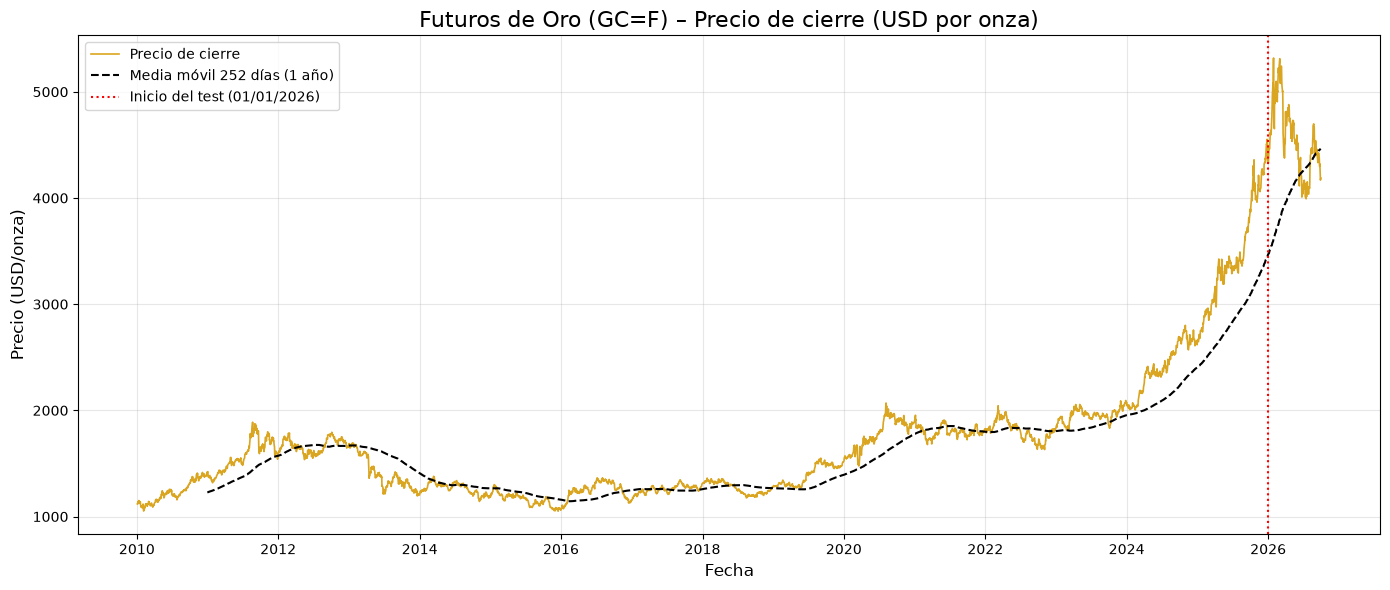

In [8]:
plt.figure(figsize=(14, 6))
plt.plot(serie_close['Close'], color='goldenrod', lw=1.2, label='Precio de cierre')
plt.plot(serie_close['Close'].rolling(252).mean(), color='black', lw=1.5, ls='--', label='Media móvil 252 días (1 año)')
plt.axvline(pd.Timestamp('2026-01-01'), color='red', ls=':', label='Inicio del test (01/01/2026)')
plt.title('Futuros de Oro (GC=F) – Precio de cierre (USD por onza)', fontsize=16)
plt.xlabel('Fecha', fontsize=12)
plt.ylabel('Precio (USD/onza)', fontsize=12)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
# Cifras de apoyo para redactar la descripción de la serie
anual = serie_close['Close'].resample('YE').mean()
print("Periodo:", serie_close.index.min().date(), "a", serie_close.index.max().date())
print("Observaciones:", len(serie_close))
print(f"Precio inicial: {serie_close['Close'].iloc[0]:.2f} | Precio final: {serie_close['Close'].iloc[-1]:.2f}")
print(f"Mínimo: {serie_close['Close'].min():.2f} ({serie_close['Close'].idxmin().date()})")
print(f"Máximo: {serie_close['Close'].max():.2f} ({serie_close['Close'].idxmax().date()})")
print(f"Variación total: {100*(serie_close['Close'].iloc[-1]/serie_close['Close'].iloc[0]-1):.1f}%")
print("\nPrecio promedio anual:")
print(anual.round(2).to_string())

Periodo: 2010-01-04 a 2026-09-30
Observaciones: 4211
Precio inicial: 1117.70 | Precio final: 4186.70
Mínimo: 1050.80 (2015-12-17)
Máximo: 5318.40 (2026-01-29)
Variación total: 274.6%

Precio promedio anual:
Date
2010-12-31    1227.50
2011-12-31    1572.14
2012-12-31    1668.84
2013-12-31    1408.66
2014-12-31    1265.82
2015-12-31    1158.84
2016-12-31    1249.71
2017-12-31    1257.70
2018-12-31    1267.60
2019-12-31    1392.72
2020-12-31    1776.81
2021-12-31    1798.91
2022-12-31    1805.19
2023-12-31    1954.52
2024-12-31    2404.71
2025-12-31    3466.09
2026-12-31    4565.50
Freq: YE-DEC


### Prueba de estacionariedad: Dickey-Fuller aumentada (ADF)

- H0: la serie no es estacionaria (existe raíz unitaria).
- Ha: la serie es estacionaria (no existe raíz unitaria).

Si el p-valor es menor a 0.05 se rechaza H0. La prueba se aplica a la serie en niveles y a su primera diferencia.

In [10]:
from statsmodels.tsa.stattools import adfuller

def prueba_adf(x, nombre):
    resultado = adfuller(x)
    print(f"--- {nombre} ---")
    print("ADF Statistic:", round(resultado[0], 4))
    print("p-value:", resultado[1])
    print("Valores críticos:", {k: round(v, 4) for k, v in resultado[4].items()})
    if resultado[1] < 0.05:
        print("Al 95% de confianza, la serie es estacionaria (rechazamos H0 de raíz unitaria).\n")
    else:
        print("Al 95% de confianza, la serie no es estacionaria (no rechazamos H0).\n")

prueba_adf(serie_close['Close'], "Precio de cierre (niveles)")
prueba_adf(serie_close['Close'].diff().dropna(), "Primera diferencia del precio")

--- Precio de cierre (niveles) ---
ADF Statistic: 0.5752
p-value: 0.986986856301335
Valores críticos: {'1%': np.float64(-3.4319), '5%': np.float64(-2.8622), '10%': np.float64(-2.5671)}
Al 95% de confianza, la serie no es estacionaria (no rechazamos H0).

--- Primera diferencia del precio ---
ADF Statistic: -10.2112
p-value: 5.6326295410280985e-18
Valores críticos: {'1%': np.float64(-3.4319), '5%': np.float64(-2.8622), '10%': np.float64(-2.5671)}
Al 95% de confianza, la serie es estacionaria (rechazamos H0 de raíz unitaria).



## Entrenamiento y validación

In [11]:
fecha_corte = '2025-12-31'
train_close = serie_close.loc[:fecha_corte]
test_close  = serie_close.loc['2026-01-01':'2026-09-30']
print("Train:", train_close.shape, train_close.index.min().date(), "-", train_close.index.max().date())
print("Test :", test_close.shape,  test_close.index.min().date(),  "-", test_close.index.max().date())

Train: (4024, 1) 2010-01-04 - 2025-12-31
Test : (187, 1) 2026-01-02 - 2026-09-30


### Funciones de apoyo (rezagos, métricas e IEC)

In [12]:
# Genera los rezagos (lags) del precio de cierre
def make_lags(df, n_lags):
    data = df.copy()
    for i in range(1, n_lags + 1):
        data[f"lag_{i}"] = data["Close"].shift(i)
    return data.dropna()

#
def IEC(mse, rmse, mae, mape):
    mse_n  = mse  / (1 + mse)
    rmse_n = rmse / (1 + rmse)
    mae_n  = mae  / (1 + mae)
    mape_n = mape / (1 + mape)

    iec = np.mean([mse_n, rmse_n, mae_n, mape_n])
    return iec

# Calcula todas las métricas de error
def calcular_metricas(y_real, y_pred):
    y_real = np.asarray(y_real).ravel()
    y_pred = np.asarray(y_pred).ravel()
    mse  = metrics.mean_squared_error(y_real, y_pred)
    rmse = np.sqrt(mse)
    mae  = metrics.mean_absolute_error(y_real, y_pred)
    mape = 100 * metrics.mean_absolute_percentage_error(y_real, y_pred)
    return {"MSE": mse, "RMSE": rmse, "MAE": mae, "MAPE": mape, "IEC": IEC(mse, rmse, mae, mape)}

### Random Forest, Deep Learning y AutoML con H2O

In [13]:
h2o.init()
h2o.no_progress()

Checking whether there is an H2O instance running at http://localhost:54321..... not found.
Attempting to start a local H2O server...
; OpenJDK 64-Bit Server VM Temurin-17.0.20.1+1 (build 17.0.20.1+1, mixed mode, sharing)
  Starting server from C:\Users\andre\AppData\Local\Programs\Python\Python313\Lib\site-packages\h2o\backend\bin\h2o.jar
  Ice root: C:\Users\andre\AppData\Local\Temp\tmpmhe4pcn2
  JVM stdout: C:\Users\andre\AppData\Local\Temp\tmpmhe4pcn2\h2o_andre_started_from_python.out
  JVM stderr: C:\Users\andre\AppData\Local\Temp\tmpmhe4pcn2\h2o_andre_started_from_python.err
  Server is running at http://127.0.0.1:54321
Connecting to H2O server at http://127.0.0.1:54321 ... successful.


H2O_cluster_uptime:,01 secs
H2O_cluster_timezone:,America/Bogota
H2O_data_parsing_timezone:,UTC
H2O_cluster_version:,3.46.0.12
H2O_cluster_version_age:,3 months and 5 days
H2O_cluster_name:,H2O_from_python_andre_3h5qh6
H2O_cluster_total_nodes:,1
H2O_cluster_free_memory:,3.934 Gb
H2O_cluster_total_cores:,16
H2O_cluster_allowed_cores:,16
H2O_cluster_status:,"locked, healthy"



+------------------------------------------------------------------+
| You are running the community edition of H2O-3 OSS.              |
|                                                                  |
| For commercial use, H2O-3 Secure is now recommended.             |
| This includes production support, CVE fixes, multi-node scaling, |
| model artifact extraction, and more.                             |
| See h2o.ai/h2o-3/oss-vs-secure for additional details.           |
| Contact enterprise@h2o.ai to upgrade.                            |
+------------------------------------------------------------------+


In [14]:
lista_lags = [10, 5, 1]
resultados_h2o = []          # métricas de cada modelo y número de lags
predicciones_h2o = {}        # predicciones para graficar

for n_lags in lista_lags:
    print(f"\n===== Entrenando modelos con {n_lags} lag(s) =====")

    # 1. Matriz de rezagos y división train/test por fecha
    data = make_lags(serie_close, n_lags)
    train_df = data.loc[:fecha_corte]
    test_df  = data.loc['2026-01-01':'2026-09-30']

    X_h2o = [f"lag_{i}" for i in range(1, n_lags + 1)]
    y_h2o = "Close"

    train_h2o = h2o.H2OFrame(train_df.reset_index(drop=True))
    test_h2o  = h2o.H2OFrame(test_df.reset_index(drop=True))

    # 2. Random Forest
    rf = H2ORandomForestEstimator(ntrees=200, max_depth=20, seed=SEED)
    rf.train(x=X_h2o, y=y_h2o, training_frame=train_h2o)
    pred_rf = rf.predict(test_h2o).as_data_frame()['predict'].values

    # 3. Deep Learning (red neuronal multicapa)
    dl = H2ODeepLearningEstimator(hidden=[64, 32], epochs=100, activation="Rectifier",
                                  seed=SEED, reproducible=True)
    dl.train(x=X_h2o, y=y_h2o, training_frame=train_h2o)
    pred_dl = dl.predict(test_h2o).as_data_frame()['predict'].values

    # 4. AutoML
    # Sin max_runtime_secs: H2O solo garantiza reproducibilidad si AutoML se limita por max_models
    aml = H2OAutoML(max_models=10, seed=SEED, nfolds=5,
                    sort_metric="RMSE", project_name=f"automl_oro_{n_lags}lags")
    aml.train(x=X_h2o, y=y_h2o, training_frame=train_h2o)
    print("Mejor modelo AutoML:", aml.leader.model_id)
    pred_aml = aml.leader.predict(test_h2o).as_data_frame()['predict'].values

    # 5. Métricas sobre la muestra de validación (test)
    for nombre, pred in [("Random Forest", pred_rf), ("DeepLearning", pred_dl), ("AutoML", pred_aml)]:
        m = calcular_metricas(test_df["Close"].values, pred)
        m.update({"Modelo": nombre, "Lags": n_lags})
        resultados_h2o.append(m)
        predicciones_h2o[(nombre, n_lags)] = pd.Series(pred, index=test_df.index)


===== Entrenando modelos con 10 lag(s) =====

18:28:36.147: AutoML: XGBoost is not available; skipping it.

Mejor modelo AutoML: StackedEnsemble_BestOfFamily_1_AutoML_1_20261116_182836

===== Entrenando modelos con 5 lag(s) =====

18:29:09.502: AutoML: XGBoost is not available; skipping it.

Mejor modelo AutoML: StackedEnsemble_AllModels_1_AutoML_2_20261116_182909

===== Entrenando modelos con 1 lag(s) =====

18:29:27.143: AutoML: XGBoost is not available; skipping it.

Mejor modelo AutoML: GBM_2_AutoML_3_20261116_182927


In [15]:
# Detalle de todas las métricas
detalle_h2o = pd.DataFrame(resultados_h2o)[["Modelo", "Lags", "MSE", "RMSE", "MAE", "MAPE", "IEC"]]
detalle_h2o

,Modelo,Lags,MSE,RMSE,MAE,MAPE,IEC
0,Random Forest,10,131329.983243,362.394789,261.785571,5.407875,0.959344
1,DeepLearning,10,22759.764678,150.863397,113.412748,2.390966,0.922432
2,AutoML,10,132239.150922,363.647014,262.278841,5.412410,0.959376
3,Random Forest,5,129279.324471,359.554341,258.717751,5.345281,0.958943
4,DeepLearning,5,12152.356566,110.237728,81.979422,1.745770,0.903670
5,AutoML,5,109155.223454,330.386476,235.812235,4.866566,0.955573
6,Random Forest,1,120671.249614,347.377676,243.059253,5.003469,0.956613
7,DeepLearning,1,29067.524488,170.492007,123.121497,2.559998,0.926295
8,AutoML,1,127753.325364,357.425972,253.625166,5.220734,0.958131


In [16]:
# Cuadro comparativo solicitado: IEC por modelo y número de lags
cuadro_a = (detalle_h2o.pivot(index="Modelo", columns="Lags", values="IEC")
            .reindex(index=["Random Forest", "DeepLearning", "AutoML"], columns=[10, 5, 1]))
cuadro_a.columns = ["IEC con 10 lags", "IEC con 5 lags", "IEC con 1 lag"]
cuadro_a

,IEC con 10 lags,IEC con 5 lags,IEC con 1 lag
Modelo,,,
Random Forest,0.959344,0.958943,0.956613
DeepLearning,0.922432,0.903670,0.926295
AutoML,0.959376,0.955573,0.958131


In [17]:
mejor = detalle_h2o.loc[detalle_h2o["IEC"].idxmin()]
print(f"Mejor combinación: {mejor['Modelo']} con {mejor['Lags']} lag(s) | IEC = {mejor['IEC']:.6f} | MAPE = {mejor['MAPE']:.2f}%")

Mejor combinación: DeepLearning con 5 lag(s) | IEC = 0.903670 | MAPE = 1.75%


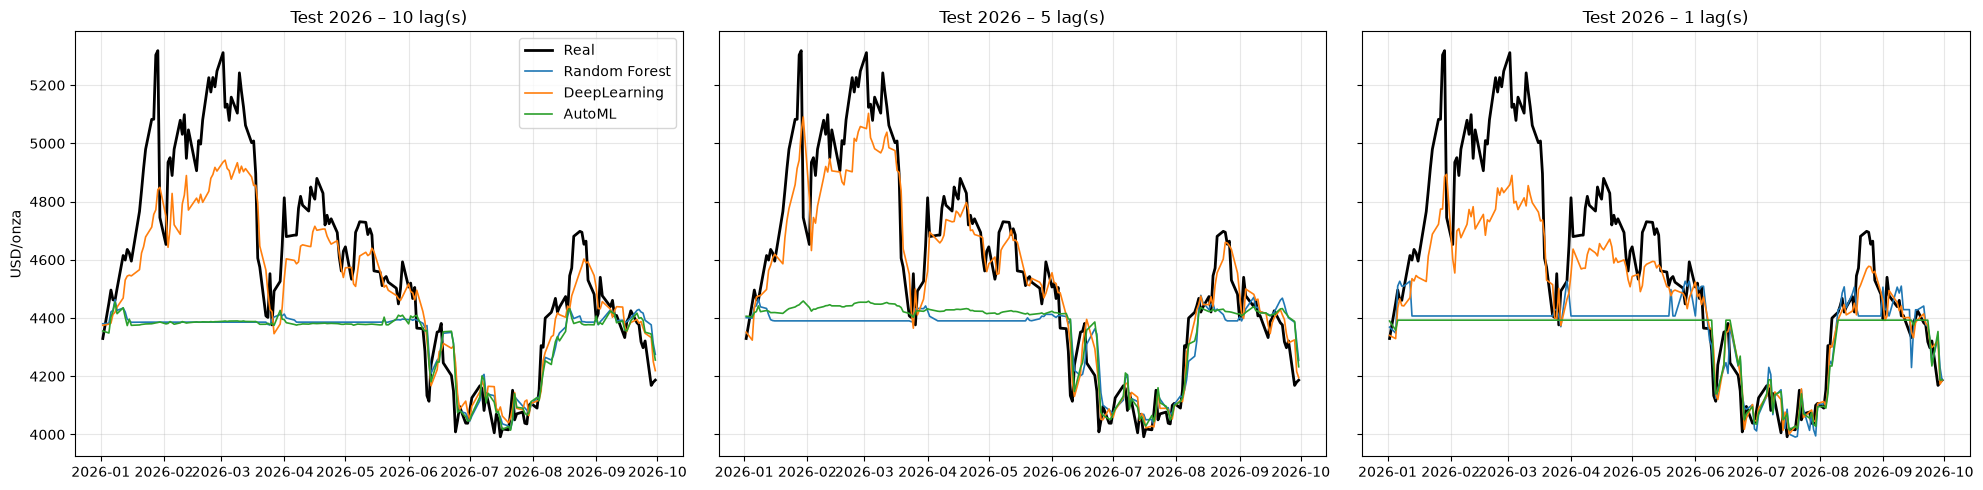

In [18]:
# Pronóstico vs. valores reales en el test
fig, axes = plt.subplots(1, 3, figsize=(20, 5), sharey=True)
for ax, n_lags in zip(axes, lista_lags):
    ax.plot(test_close['Close'], color='black', lw=2, label='Real')
    for nombre in ["Random Forest", "DeepLearning", "AutoML"]:
        ax.plot(predicciones_h2o[(nombre, n_lags)], lw=1.2, label=nombre)
    ax.set_title(f"Test 2026 – {n_lags} lag(s)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("USD/onza")
axes[0].legend()
plt.tight_layout()
plt.show()

### LSTM y GRU con 2 épocas

Se usa una ventana de 60 días (como en clase). El escalador MinMax se ajusta solo con el train para no filtrar información del test.

In [19]:
dataset = serie_close.values                      # precio de cierre
training_data_len = len(train_close)              # observaciones hasta el 31/12/2025
test_end = training_data_len + len(test_close)    # observaciones hasta el 30/09/2026
ventana = 60

scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(dataset[:training_data_len])
scaled_data = scaler.transform(dataset[:test_end])

# Dataset de entrenamiento
train_data = scaled_data[:training_data_len, :]
x_train, y_train = [], []
for i in range(ventana, len(train_data)):
    x_train.append(train_data[i-ventana:i, 0])
    y_train.append(train_data[i, 0])
x_train, y_train = np.array(x_train), np.array(y_train)
x_train = np.reshape(x_train, (x_train.shape[0], x_train.shape[1], 1))

# Dataset de test (usa los últimos 60 días del train como contexto)
test_data = scaled_data[training_data_len - ventana:test_end, :]
x_test = []
y_test = dataset[training_data_len:test_end, :]
for i in range(ventana, len(test_data)):
    x_test.append(test_data[i-ventana:i, 0])
x_test = np.array(x_test)
x_test = np.reshape(x_test, (x_test.shape[0], x_test.shape[1], 1))

print("x_train:", x_train.shape, "| x_test:", x_test.shape, "| y_test:", y_test.shape)

x_train: (3964, 60, 1) | x_test: (187, 60, 1) | y_test: (187, 1)


#### Modelado con LSTM

In [20]:
keras.utils.set_random_seed(SEED)
model_lstm = Sequential()
model_lstm.add(Input(shape=(x_train.shape[1], 1)))
model_lstm.add(LSTM(128, return_sequences=True, activation='relu'))
model_lstm.add(LSTM(64, return_sequences=False))
model_lstm.add(Dense(25))
model_lstm.add(Dense(1))
model_lstm.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 60, 128)             │          66,560 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 64)                  │          49,408 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 25)                  │           1,625 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              26 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 117,619 (459.45 KB)

 Trainable params: 117,619 (459.45 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
model_lstm.compile(optimizer='adam', loss='mean_squared_error')
model_lstm.fit(x_train, y_train, batch_size=1, epochs=2)

Epoch 1/2
3964/3964 ━━━━━━━━━━━━━━━━━━━━ 83s 20ms/step - loss: 7.7403e-04
Epoch 2/2
3964/3964 ━━━━━━━━━━━━━━━━━━━━ 83s 21ms/step - loss: 3.8322e-04


In [22]:
predictions_lstm = scaler.inverse_transform(model_lstm.predict(x_test))
met_lstm = calcular_metricas(y_test, predictions_lstm)
met_lstm

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step


{'MSE': 16738.493440161732,
 'RMSE': np.float64(129.37732969945597),
 'MAE': 98.00309549423463,
 'MAPE': 2.122152928564104,
 'IEC': np.float64(0.9154694289204204)}

#### Modelado con GRU

In [23]:
keras.utils.set_random_seed(SEED)
model_gru = Sequential()
model_gru.add(Input(shape=(x_train.shape[1], 1)))
model_gru.add(GRU(50, return_sequences=True, activation='relu'))
model_gru.add(GRU(64, return_sequences=False))
model_gru.add(Dense(25))
model_gru.add(Dense(1))
model_gru.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ gru (GRU)                            │ (None, 60, 50)              │           7,950 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ gru_1 (GRU)                          │ (None, 64)                  │          22,272 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 25)                  │           1,625 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │              26 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 31,873 (124.50 KB)

 Trainable params: 31,873 (124.50 KB)

 Non-trainable params: 0 (0.00 B)

In [24]:
model_gru.compile(optimizer='adam', loss='mean_squared_error')
model_gru.fit(x_train, y_train, batch_size=1, epochs=2)

Epoch 1/2
3964/3964 ━━━━━━━━━━━━━━━━━━━━ 76s 19ms/step - loss: 3.8030e-04
Epoch 2/2
3964/3964 ━━━━━━━━━━━━━━━━━━━━ 83s 19ms/step - loss: 2.2057e-04


In [25]:
predictions_gru = scaler.inverse_transform(model_gru.predict(x_test))
met_gru = calcular_metricas(y_test, predictions_gru)
met_gru

6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 65ms/step


{'MSE': 26055.86997223506,
 'RMSE': np.float64(161.41830742587737),
 'MAE': 141.8814664626504,
 'MAPE': 3.0655200010819925,
 'IEC': np.float64(0.9352087194077269)}

#### Cuadro comparativo LSTM vs. GRU

In [26]:
cuadro_b = pd.DataFrame([met_lstm, met_gru], index=["LSTM", "GRU"])[["MSE", "RMSE", "MAE", "MAPE", "IEC"]]
cuadro_b.index.name = "Modelos"
cuadro_b

,MSE,RMSE,MAE,MAPE,IEC
Modelos,,,,,
LSTM,16738.493440,129.377330,98.003095,2.122153,0.915469
GRU,26055.869972,161.418307,141.881466,3.065520,0.935209


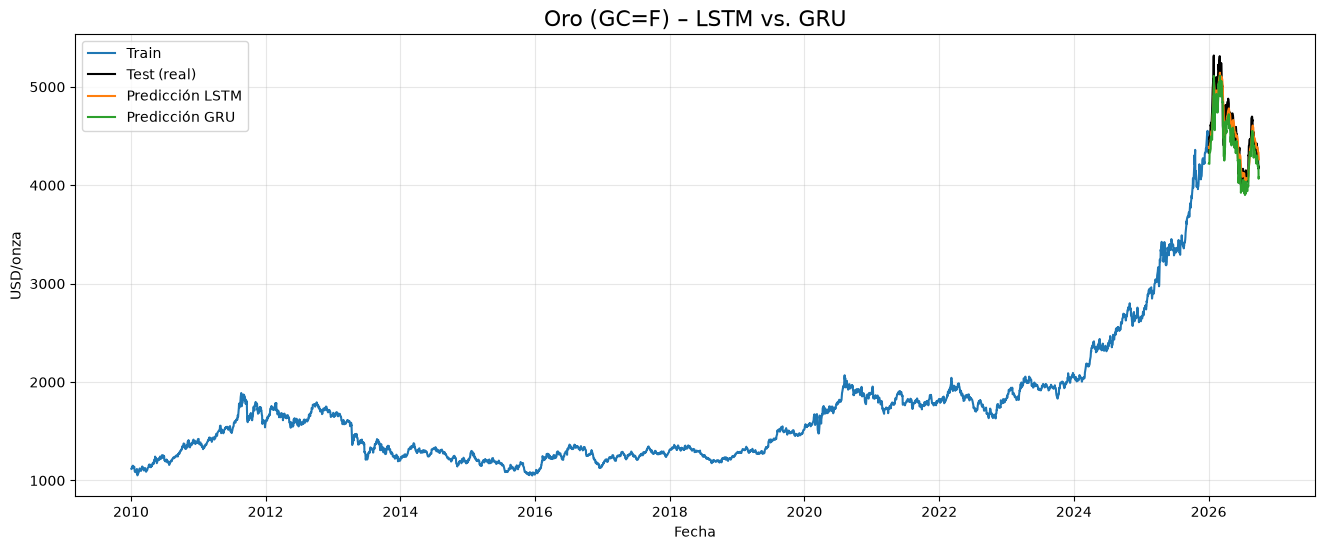

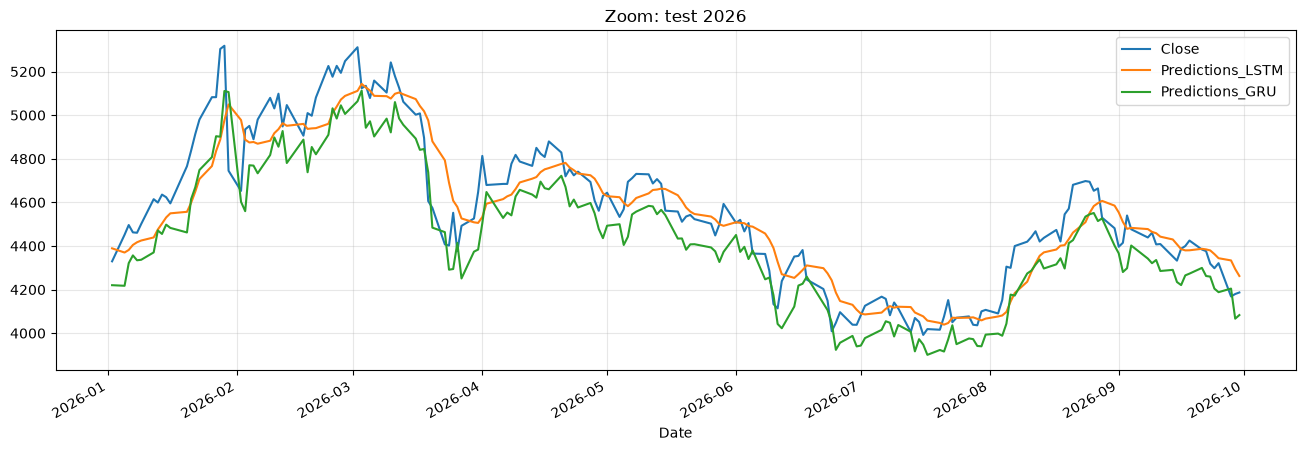

In [27]:
valid = test_close.copy()
valid['Predictions_LSTM'] = predictions_lstm
valid['Predictions_GRU']  = predictions_gru

plt.figure(figsize=(16, 6))
plt.plot(train_close['Close'], label='Train')
plt.plot(valid['Close'], label='Test (real)', color='black')
plt.plot(valid['Predictions_LSTM'], label='Predicción LSTM')
plt.plot(valid['Predictions_GRU'],  label='Predicción GRU')
plt.title('Oro (GC=F) – LSTM vs. GRU', fontsize=16)
plt.xlabel('Fecha'); plt.ylabel('USD/onza')
plt.legend(); plt.grid(alpha=0.3); plt.show()

# Zoom al periodo de test
valid[['Close', 'Predictions_LSTM', 'Predictions_GRU']].plot(figsize=(16, 5), title='Zoom: test 2026')
plt.grid(alpha=0.3); plt.show()

### Comparación final de todos los modelos

In [28]:
comparacion = pd.concat([
    detalle_h2o.assign(Modelo=detalle_h2o["Modelo"] + " (" + detalle_h2o["Lags"].astype(str) + " lags)")
               .set_index("Modelo")[["MSE", "RMSE", "MAE", "MAPE", "IEC"]],
    cuadro_b
]).sort_values("IEC")
comparacion

,MSE,RMSE,MAE,MAPE,IEC
DeepLearning (5 lags),12152.356566,110.237728,81.979422,1.745770,0.903670
LSTM,16738.493440,129.377330,98.003095,2.122153,0.915469
DeepLearning (10 lags),22759.764678,150.863397,113.412748,2.390966,0.922432
DeepLearning (1 lags),29067.524488,170.492007,123.121497,2.559998,0.926295
GRU,26055.869972,161.418307,141.881466,3.065520,0.935209
AutoML (5 lags),109155.223454,330.386476,235.812235,4.866566,0.955573
Random Forest (1 lags),120671.249614,347.377676,243.059253,5.003469,0.956613
AutoML (1 lags),127753.325364,357.425972,253.625166,5.220734,0.958131
Random Forest (5 lags),129279.324471,359.554341,258.717751,5.345281,0.958943
Random Forest (10 lags),131329.983243,362.394789,261.785571,5.407875,0.959344


### Apagar el clúster H2O

In [29]:
h2o.cluster().shutdown()

H2O session _sid_ada2 closed.
